# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib scipy joblib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
kernel: d:\Repo Aprendizaje Automatico\AprendizajeAutomatico\.venv\Scripts\python.exe



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.14.1+cpu | dispositivo: cpu


## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [3]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 2
Estado siguiente: [ 0.004  1.426  0.217  0.344 -0.006 -0.067  0.     0.   ]
Recompensa: -2.497
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [4]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [5]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [6]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [7]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


In [8]:
# Implementación del agente DQN
class AgenteDQN(Agente):
    """
    Agente DQN (Deep Q-Network).
    Implementa aproximación de función con redes neuronales,
    Experience Replay y Target Network desacoplada.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 gamma=0.95, lr=1e-4, batch_size=32, buffer_size=100_000,
                 tau=1e-2, epsilon_start=1.0, epsilon_min=0.01, epsilon_decay=0.99,
                 # Arquitectura de la red: un ancho por capa oculta
                 capas_ocultas=(128, 128),
                 # Interruptores para el estudio de ablación (sección 11)
                 usar_target_net=True, usar_replay_buffer=True, usar_huber=True):
        
        # -------------------------------------------------------------
        # 1. SEMILLAS ALEATORIAS (Reproducibilidad)
        # -------------------------------------------------------------
        # Fijamos la semilla en todos los generadores involucrados:
        # random (Python puro), numpy, torch y el espacio de acciones de Gymnasium.
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)

        self.accion_space = accion_space
        # LunarLander tiene 8 dimensiones en observación y 4 acciones discretas
        self.num_estados = estado_space.shape[0]   # 8
        self.num_acciones = accion_space.n        # 4
        
        # -------------------------------------------------------------
        # 2. HIPERPARÁMETROS
        # -------------------------------------------------------------
        self.gamma = gamma                    # Factor de descuento de Bellman
        self.batch_size = batch_size          # Tamaño del lote para optimizar
        self.tau = tau                        # Tasa para el Soft Update (mezcla suave)
        self.epsilon = epsilon_start          # Probabilidad inicial de exploración
        self.epsilon_min = epsilon_min        # Cota inferior de exploración
        self.epsilon_decay = epsilon_decay    # Factor de decaimiento por episodio
        
        # Ablación: con False, el componente correspondiente se desactiva
        self.usar_target_net = usar_target_net          # False: el objetivo usa red_q
        self.usar_replay_buffer = usar_replay_buffer    # False: aprende solo de la última transición
        self.funcion_perdida = F.smooth_l1_loss if usar_huber else F.mse_loss

        # -------------------------------------------------------------
        # 3. REDES NEURONALES (PyTorch)
        # -------------------------------------------------------------
        # Perceptrón Multicapa (MLP) con ReLU: por defecto [8 -> 64 -> 64 -> 4]
        def construir_red():
            capas, entrada = [], self.num_estados
            for ancho in capas_ocultas:
                capas += [nn.Linear(entrada, ancho), nn.ReLU()]
                entrada = ancho
            return nn.Sequential(*capas, nn.Linear(entrada, self.num_acciones))

        # Red Principal (Policy Network): se optimiza activamente con gradiente descendente
        self.red_q = construir_red()
        
        # Red Objetivo (Target Network): red desacoplada para estabilizar el cálculo de Bellman
        self.red_target = construir_red()
        self.red_target.load_state_dict(self.red_q.state_dict())
        self.red_target.eval()

        # Optimizador Adam: se encarga de aplicar los gradientes sobre los pesos de red_q
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

        # -------------------------------------------------------------
        # 4. EXPERIENCE REPLAY BUFFER
        # -------------------------------------------------------------
        # Cola de memoria circular con capacidad máxima fija
        self.memoria = deque(maxlen=buffer_size)

    # =================================================================
    # POLÍTICA DE SELECCIÓN DE ACCIÓN (Epsilon-Greedy)
    # =================================================================
    def elegir_accion(self, estado, explorar=True):
        """
        Dada una observación del entorno, decide qué acción tomar (0, 1, 2 o 3).
        Con explorar=True aplica la política epsilon-greedy.
        Con explorar=False (evaluación), elige la mejor acción determinista (greedy).
        """
        # Exploración: acción aleatoria uniforme
        if explorar and random.random() < self.epsilon:
            return self.accion_space.sample()
        
        # Explotación: consultamos la red neuronal (greedy)
        # 1) Convertimos el array de NumPy a tensor de PyTorch.
        # 2) .unsqueeze(0) agrega la dimensión del lote: pasa de tamaño (8,) a (1, 8).
        estado_t = torch.as_tensor(estado, dtype=torch.float32).unsqueeze(0)
        
        # torch.no_grad() desactiva el cálculo de gradientes durante la inferencia
        with torch.no_grad():
            q_valores = self.red_q(estado_t)  # Salida: tensor (1, 4)
            
        # .argmax(dim=1) devuelve el índice con el mayor valor Q, y .item() lo convierte a int
        return int(q_valores.argmax(dim=1).item())

    # =================================================================
    # APRENDIZAJE Y GUARDADO DE EXPERIENCIAS
    # =================================================================
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """
        Almacena la transición en el buffer y ejecuta un paso de optimización
        cuando hay suficientes experiencias acumuladas.
        """
        # 1. Guardar la transición (s, a, r, s', terminado) en el Replay Buffer
        self.memoria.append((estado, accion, recompensa, siguiente_estado, terminado))
        
        # 2. Entrenar la red solo si acumulamos al menos un lote completo
        # (sin Replay Buffer se aprende de inmediato, de la transición recién vista)
        if not self.usar_replay_buffer or len(self.memoria) >= self.batch_size:
            self._optimizar_red()

    def fin_episodio(self):
        """
        Invocado por el bucle de entrenamiento al terminar cada episodio.
        Aplica el decaimiento de epsilon para reducir la exploración gradualmente.
        """
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    # =================================================================
    # MÉTODOS AUXILIARES INTERNOS
    # =================================================================
    def _optimizar_red(self):
        """
        Extrae un lote de experiencias del buffer, calcula la pérdida de Bellman
        y actualiza los pesos de red_q mediante backpropagation.
        """
        # 1. Muestreo de experiencias (sin Replay Buffer, solo la última transición)
        if self.usar_replay_buffer:
            lote = random.sample(self.memoria, self.batch_size)
        else:
            lote = [self.memoria[-1]]

        # zip(*lote) transpone la lista de tuplas a tuplas por componente
        estados, acciones, recompensas, sig_estados, terminados = zip(*lote)

        # 2. Conversión a Tensores de PyTorch
        estados_t = torch.as_tensor(np.array(estados), dtype=torch.float32)                   # (64, 8)
        acciones_t = torch.as_tensor(acciones, dtype=torch.int64).unsqueeze(1)               # (64, 1)
        recompensas_t = torch.as_tensor(recompensas, dtype=torch.float32).unsqueeze(1)       # (64, 1)
        sig_estados_t = torch.as_tensor(np.array(sig_estados), dtype=torch.float32)           # (64, 8)
        terminados_t = torch.as_tensor(terminados, dtype=torch.float32).unsqueeze(1)         # (64, 1)

        # 3. Predicción actual: Q(s, a; θ)
        # .gather(1, acciones_t) extrae únicamente el valor Q de la acción que efectivamente se tomó
        q_pred = self.red_q(estados_t).gather(1, acciones_t)

        # 4. Cálculo del Objetivo de Bellman: y = r + γ * max_a' Q(s', a'; θ⁻) * (1 - terminado)
        with torch.no_grad():
            red_objetivo = self.red_target if self.usar_target_net else self.red_q
            q_siguiente = red_objetivo(sig_estados_t).max(1, keepdim=True)[0]
            target_bellman = recompensas_t + (1.0 - terminados_t) * self.gamma * q_siguiente

        # 5. Cálculo de Error y Backpropagation
        # Pérdida Smooth L1 (Huber Loss): robusta ante outliers y saltos bruscos
        # (con usar_huber=False es la MSE clásica)
        perdida = self.funcion_perdida(q_pred, target_bellman)

        self.optimizador.zero_grad()  # Limpia los gradientes acumulados
        perdida.backward()            # Calcula las derivadas parciales (Autograd)
        self.optimizador.step()        # Actualiza los pesos de red_q aplicando la regla de Adam

        # 6. Actualización Suave de la Red Objetivo (Soft Update)
        # Sin target network no hay nada que actualizar
        if self.usar_target_net:
            self._actualizar_target()

    def _actualizar_target(self):
        """
        Soft update (Promedio de Polyak):
        θ_target = τ * θ_local + (1 - τ) * θ_target
        Actualiza suavemente la red objetivo mezclando una fracción tau de los pesos en cada paso.
        """
        for param_q, param_target in zip(self.red_q.parameters(), self.red_target.parameters()):
            param_target.data.copy_(self.tau * param_q.data + (1.0 - self.tau) * param_target.data)

### 6.1 Calibración de hiperparámetros

Antes de entrenar el agente definitivo y de hacer la ablación se eligen los hiperparámetros con evidencia, no a ojo.
Probar todas las combinaciones es inviable, así que la calibración es **por etapas**: en cada una se varía un grupo
de parámetros con el resto fijo en el mejor valor encontrado hasta ese momento, y se pasa a la siguiente.

| Etapa | Qué se varía |
|---|---|
| 1 | tasa de aprendizaje `lr` |
| 2 | arquitectura: capas ocultas y neuronas por capa |
| 3 | factor de descuento `gamma` |
| 4 | tasa del soft update `tau` |
| 5 | exploración: `epsilon_decay` y `epsilon_min` |
| 6 | tamaño del lote y del replay buffer |
| Confirmación | la configuración elegida contra la inicial, con más episodios y semillas nuevas |

* **Semillas propias.** Cada configuración se entrena con 3 semillas (100–102), distintas de las del estudio de
  ablación (0–9). Así la configuración elegida no llega a la ablación habiendo sido seleccionada sobre las mismas corridas.
* **Escenarios de evaluación propios.** La calibración y la confirmación evalúan sin exploración sobre 100
  escenarios con semilla base 20 000, los mismos para todas las configuraciones. La evaluación de la ablación y la
  final (sección 8) usan la semilla 10 000 de la consigna, de modo que esos escenarios no intervienen en la elección
  de hiperparámetros.
* **Criterio.** Gana la configuración con mayor recompensa de evaluación promedio entre semillas (evaluación sin
  exploración); la peor semilla desempata y, si empatan del todo, se conserva el valor de partida. Si la diferencia con la segunda
  es menor que la dispersión entre semillas, la celda lo avisa: con 3 semillas esa elección es poco concluyente.
* **Presupuesto en dos niveles.** Las etapas usan 600 episodios, menos que los 900 de la ablación, para acotar el
  cómputo. Lo elegido se confirma al final a 900 episodios contra la configuración inicial, con 5 semillas nuevas
  (103–107) y un test de Mann-Whitney; si no supera a la inicial en media, se conserva la inicial.
* **Cómputo.** Las corridas se reparten entre procesos y cada resultado se guarda en disco junto con la
  configuración con la que se obtuvo (`resultados_calibracion_*.json`): se puede interrumpir y retomar, y una corrida
  guardada con otra configuración se vuelve a entrenar sola.
* **Orden.** Las etapas se ejecutan en orden: cada una parte de lo elegido por la anterior.
* Los valores elegidos quedan en el diccionario `HIPERPARAMETROS`, que usan después el entrenamiento principal
  (sección 7) y la ablación (sección 11).

In [9]:
# Infraestructura de la calibración y de la ablación: entrenar y evaluar muchas configuraciones en paralelo
import inspect
import json
import os
from concurrent.futures import as_completed
from itertools import product
from pathlib import Path

from joblib.externals.loky import get_reusable_executor

EPISODIOS_EVALUACION = 100
SEMILLA_EVALUACION = 10_000               # la de la consigna (agente aleatorio, sección 8): evaluación de la ablación y final
SEMILLA_EVALUACION_CALIBRACION = 20_000   # otros escenarios para elegir hiperparámetros: así los de 10_000 no intervienen en la elección
NUM_PROCESOS = max(1, (os.cpu_count() or 2) - 1)   # se deja un núcleo libre para el sistema

SEMILLAS_CALIBRACION = [100, 101, 102]    # distintas de las de la ablación
EPISODIOS_CALIBRACION = 600               # menos que los 900 de la ablación, para acotar el cómputo
EPISODIOS_CONFIRMACION = 900              # presupuesto de la ablación: la configuración final se confirma a este
SEMILLAS_CONFIRMACION = [103, 104, 105, 106, 107]   # nuevas: ni las de la selección ni las de la ablación


def valores_por_defecto(funcion):
    return {nombre: p.default for nombre, p in inspect.signature(funcion).parameters.items()
            if p.default is not inspect.Parameter.empty}


# Hiperparámetros que se calibran. Arrancan en los valores por defecto del agente y cada etapa los actualiza.
HIPERPARAMETROS = {clave: valor for clave, valor in valores_por_defecto(AgenteDQN.__init__).items()
                   if clave in ('capas_ocultas', 'lr', 'gamma', 'tau', 'epsilon_decay', 'epsilon_min',
                                'batch_size', 'buffer_size')}
HIPERPARAMETROS_INICIALES = dict(HIPERPARAMETROS)


# Punto de partida de cada etapa, fijado la primera vez que corre: si se vuelve a ejecutar una etapa
# suelta, no cambia de base (y reutiliza lo guardado) aunque las siguientes ya hayan actualizado
# HIPERPARAMETROS. Ejecutar de nuevo esta celda reinicia la calibración.
BASES_ETAPAS = {}


def configuracion_corrida(config, episodios, semilla_evaluacion):
    """Todo lo que determina el resultado de una corrida, salvo la semilla. Se guarda junto al
    resultado: si algo de esto cambia, la corrida guardada ya no vale y se vuelve a entrenar."""
    completa = {
        'episodios_entrenamiento': episodios,
        'episodios_evaluacion': EPISODIOS_EVALUACION,
        'semilla_evaluacion': semilla_evaluacion,
        'entrenamiento': {k: v for k, v in valores_por_defecto(entrenar_agente).items()
                          if k in ('max_pasos', 'umbral_resolucion')},
        'agente': {**valores_por_defecto(AgenteDQN.__init__), **config},
    }
    return json.loads(json.dumps(completa))   # pasa por JSON para compararla con la leída del archivo


def entrenar_y_evaluar(config, semilla, episodios, semilla_evaluacion):
    """Entrena un DQN desde cero con la semilla dada y lo evalúa sin exploración.
    Corre en un proceso aparte; cada corrida fija sus semillas al crear el agente, así que el
    resultado no depende del orden en que los procesos tomen las tareas."""
    torch.set_num_threads(1)   # un hilo por proceso: con varios procesos en paralelo, más hilos se estorban
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla, **config)
    entrenar_agente(agente, env, num_episodios=episodios, semilla=semilla, verbose=False)
    resultados = evaluar_agente(agente, env, num_episodios=EPISODIOS_EVALUACION,
                                semilla=semilla_evaluacion)
    env.close()
    return {'recompensa_promedio': resultados['recompensa_promedio'],
            'tasa_exito': resultados['tasa_exito']}


def guardar(resultados, archivo):
    temporal = archivo.with_suffix('.tmp')   # escritura atómica: una interrupción no deja el JSON a medias
    temporal.write_text(json.dumps(resultados, indent=1))
    temporal.replace(archivo)


def correr_estudio(configuraciones, archivo, semillas, episodios,
                   semilla_evaluacion=SEMILLA_EVALUACION, num_procesos=NUM_PROCESOS):
    """Entrena y evalúa cada configuración con cada semilla, en paralelo. Cada resultado se guarda
    en disco al terminar, junto con la configuración con la que se obtuvo, para poder retomar o
    re-analizar sin reentrenar. Una corrida guardada solo se reutiliza si su configuración coincide
    con la actual; si no, se vuelve a entrenar. Lo que no se detecta es un cambio en el código del
    agente o del entrenamiento: en ese caso, borrar el archivo."""
    resultados = json.loads(archivo.read_text()) if archivo.exists() else {}

    pendientes = []
    for nombre, config in configuraciones.items():
        vigente = configuracion_corrida(config, episodios, semilla_evaluacion)
        corridas = resultados.setdefault(nombre, {})
        for semilla in semillas:
            guardada = corridas.get(str(semilla))
            if guardada is not None and guardada.get('configuracion') == vigente:
                continue
            if guardada is not None:
                print(f"{nombre} | semilla {semilla}: la corrida guardada usó otra configuración, se reentrena")
            pendientes.append((nombre, config, semilla, vigente))

    print(f"{archivo.name}: {len(pendientes)} corridas por entrenar en {num_procesos} procesos "
          f"({len(configuraciones) * len(semillas) - len(pendientes)} ya guardadas)")
    if not pendientes:
        return resultados

    ejecutor = get_reusable_executor(max_workers=num_procesos)
    futuros = {ejecutor.submit(entrenar_y_evaluar, config, semilla, episodios, semilla_evaluacion): (nombre, semilla, vigente)
               for nombre, config, semilla, vigente in pendientes}
    try:
        for terminadas, futuro in enumerate(as_completed(futuros), start=1):
            nombre, semilla, vigente = futuros[futuro]
            corrida = futuro.result()
            resultados[nombre][str(semilla)] = {**corrida, 'configuracion': vigente}
            guardar(resultados, archivo)
            print(f"[{terminadas}/{len(pendientes)}] {nombre} | semilla {semilla}: "
                  f"recompensa {corrida['recompensa_promedio']:.1f}, éxito {corrida['tasa_exito']:.0%}")
    except BaseException:
        # Error o interrupción manual: se cortan los procesos; lo ya terminado quedó guardado
        for futuro in futuros:
            futuro.cancel()
        ejecutor.shutdown(wait=False, kill_workers=True)
        raise
    return resultados


def etiqueta(cambios):
    return ", ".join(f"{clave}=" + (f"{len(valor)}x{valor[0]}" if clave == 'capas_ocultas' else f"{valor}")
                     for clave, valor in cambios.items())


def calibrar_etapa(nombre_etapa, espacio):
    """Prueba todas las combinaciones de `espacio` ({parámetro: [valores]}) con el resto de los
    hiperparámetros en su valor de partida, muestra los resultados y deja la mejor en HIPERPARAMETROS."""
    base = BASES_ETAPAS.setdefault(nombre_etapa, dict(HIPERPARAMETROS))
    configuraciones = {}
    for valores in product(*espacio.values()):
        cambios = dict(zip(espacio, valores))
        configuraciones[etiqueta(cambios)] = {**base, **cambios}

    archivo = Path(f'resultados_calibracion_{nombre_etapa}.json')
    resultados = correr_estudio(configuraciones, archivo, SEMILLAS_CALIBRACION, EPISODIOS_CALIBRACION,
                                SEMILLA_EVALUACION_CALIBRACION)

    por_config = {}
    for nombre in configuraciones:
        recompensas = np.array([resultados[nombre][str(s)]['recompensa_promedio'] for s in SEMILLAS_CALIBRACION])
        exitos = np.mean([resultados[nombre][str(s)]['tasa_exito'] for s in SEMILLAS_CALIBRACION])
        por_config[nombre] = (recompensas.mean(), recompensas.std(ddof=1), recompensas.min(), exitos, recompensas)

    # Mayor recompensa media; la peor semilla desempata y, si empatan del todo, gana el valor de partida
    ranking = sorted(por_config, key=lambda n: (por_config[n][0], por_config[n][2], configuraciones[n] == base),
                     reverse=True)
    mejor = ranking[0]

    ancho = max(len(n) for n in ranking)
    print(f"\nEtapa '{nombre_etapa}' ({len(SEMILLAS_CALIBRACION)} semillas, {EPISODIOS_CALIBRACION} episodios)")
    print(f"{'Configuración':<{ancho}}{'media':>9}{'desv.':>8}{'peor':>8}{'éxito':>8}")
    for nombre in ranking:
        media, desv, peor, exito, _ = por_config[nombre]
        marcas = ("   <- elegida" if nombre == mejor else "") + ("   (valor de partida)" if configuraciones[nombre] == base else "")
        print(f"{nombre:<{ancho}}{media:9.1f}{desv:8.1f}{peor:8.1f}{exito:8.1%}{marcas}")

    if len(ranking) > 1 and por_config[mejor][0] - por_config[ranking[1]][0] < por_config[mejor][1]:
        print(f"Aviso: la diferencia con '{ranking[1]}' es menor que la dispersión entre semillas; elección poco concluyente.")

    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(ranking)), 4))
    for posicion, nombre in enumerate(ranking):
        recompensas = por_config[nombre][4]
        ax.scatter([posicion] * len(recompensas), recompensas, alpha=0.7, color='tab:blue')
        ax.hlines(recompensas.mean(), posicion - 0.25, posicion + 0.25, linewidth=2,
                  color='tab:red' if nombre == mejor else 'black')
    ax.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax.set_xticks(range(len(ranking)))
    ax.set_xticklabels(ranking, rotation=45, ha='right', fontsize=8)
    ax.set_ylabel("Recompensa promedio de evaluación")
    ax.set_title(f"Etapa '{nombre_etapa}': un punto por semilla (línea = media, roja = elegida)")
    ax.legend(fontsize=8)
    ax.grid(True, axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()

    HIPERPARAMETROS.update({clave: configuraciones[mejor][clave] for clave in espacio})
    return resultados


print("Hiperparámetros iniciales:", HIPERPARAMETROS)

Hiperparámetros iniciales: {'gamma': 0.95, 'lr': 0.0001, 'batch_size': 32, 'buffer_size': 100000, 'tau': 0.01, 'epsilon_min': 0.01, 'epsilon_decay': 0.99, 'capas_ocultas': (128, 128)}


resultados_calibracion_lr.json: 9 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/9] lr=0.0001 | semilla 102: recompensa -87.2, éxito 0%
[2/9] lr=0.0005 | semilla 102: recompensa -28.3, éxito 1%
[3/9] lr=0.0001 | semilla 100: recompensa -60.8, éxito 0%
[4/9] lr=0.0005 | semilla 101: recompensa -69.9, éxito 0%
[5/9] lr=0.0001 | semilla 101: recompensa -59.2, éxito 0%
[6/9] lr=0.0005 | semilla 100: recompensa -80.5, éxito 0%
[7/9] lr=0.001 | semilla 102: recompensa -56.8, éxito 0%
[8/9] lr=0.001 | semilla 100: recompensa -76.4, éxito 0%
[9/9] lr=0.001 | semilla 101: recompensa -68.9, éxito 2%

Etapa 'lr' (3 semillas, 600 episodios)
Configuración    media   desv.    peor   éxito
lr=0.0005    -59.6    27.6   -80.5    0.3%   <- elegida
lr=0.001     -67.3     9.9   -76.4    0.7%
lr=0.0001    -69.1    15.8   -87.2    0.0%   (valor de partida)
Aviso: la diferencia con 'lr=0.001' es menor que la dispersión entre semillas; elección poco concluyente.


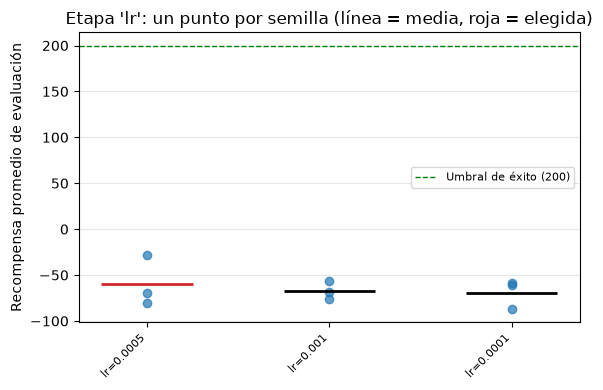

{'lr=0.0001': {'102': {'recompensa_promedio': -87.22610906932519,
   'tasa_exito': 0.0,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0001,
     'batch_size': 32,
     'buffer_size': 100000,
     'tau': 0.01,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [128, 128],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '100': {'recompensa_promedio': -60.79361068679523,
   'tasa_exito': 0.0,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0001,
     'batch_size': 32,
     'buffer_size': 1

In [10]:
# Etapa 1: tasa de aprendizaje
calibrar_etapa('lr', {'lr': [1e-4, 5e-4, 1e-3]})

resultados_calibracion_arquitectura.json: 36 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/36] capas_ocultas=1x64 | semilla 101: recompensa -77.9, éxito 0%
[2/36] capas_ocultas=1x32 | semilla 100: recompensa -75.2, éxito 0%
[3/36] capas_ocultas=1x32 | semilla 102: recompensa -55.7, éxito 0%
[4/36] capas_ocultas=1x64 | semilla 100: recompensa 19.3, éxito 4%
[5/36] capas_ocultas=1x32 | semilla 101: recompensa -42.8, éxito 0%
[6/36] capas_ocultas=1x128 | semilla 101: recompensa -61.0, éxito 0%
[7/36] capas_ocultas=1x256 | semilla 100: recompensa -81.9, éxito 0%
[8/36] capas_ocultas=1x256 | semilla 101: recompensa -40.5, éxito 0%
[9/36] capas_ocultas=1x64 | semilla 102: recompensa -66.8, éxito 0%
[10/36] capas_ocultas=1x256 | semilla 102: recompensa -37.8, éxito 0%
[11/36] capas_ocultas=1x128 | semilla 102: recompensa -58.3, éxito 0%
[12/36] capas_ocultas=1x128 | semilla 100: recompensa -45.9, éxito 0%
[13/36] capas_ocultas=2x32 | semilla 100: recompensa -80.1, éxito 0%
[14/36] 

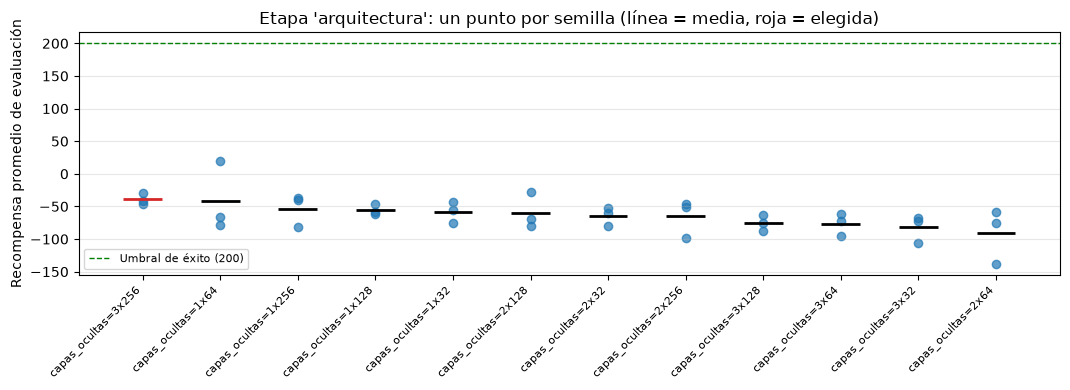

{'capas_ocultas=1x32': {'100': {'recompensa_promedio': -75.24243652398663,
   'tasa_exito': 0.0,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size': 100000,
     'tau': 0.01,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [32],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '102': {'recompensa_promedio': -55.696721411370206,
   'tasa_exito': 0.0,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size

In [11]:
# Etapa 2: arquitectura (número de capas ocultas y neuronas por capa)
calibrar_etapa('arquitectura', {'capas_ocultas': [(ancho,) * capas
                                                   for capas in (1, 2, 3) for ancho in (32, 64, 128, 256)]})

resultados_calibracion_gamma.json: 9 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/9] gamma=0.999 | semilla 102: recompensa -617.9, éxito 0%
[2/9] gamma=0.999 | semilla 101: recompensa -1048.9, éxito 0%
[3/9] gamma=0.999 | semilla 100: recompensa -592.3, éxito 0%
[4/9] gamma=0.99 | semilla 102: recompensa 189.9, éxito 61%
[5/9] gamma=0.99 | semilla 101: recompensa 196.2, éxito 73%
[6/9] gamma=0.99 | semilla 100: recompensa 169.6, éxito 14%
[7/9] gamma=0.95 | semilla 101: recompensa -29.6, éxito 2%
[8/9] gamma=0.95 | semilla 102: recompensa -45.7, éxito 0%
[9/9] gamma=0.95 | semilla 100: recompensa -42.4, éxito 0%

Etapa 'gamma' (3 semillas, 600 episodios)
Configuración    media   desv.    peor   éxito
gamma=0.99     185.2    13.9   169.6   49.3%   <- elegida
gamma=0.95     -39.2     8.5   -45.7    0.7%   (valor de partida)
gamma=0.999   -753.0   256.5 -1048.9    0.0%


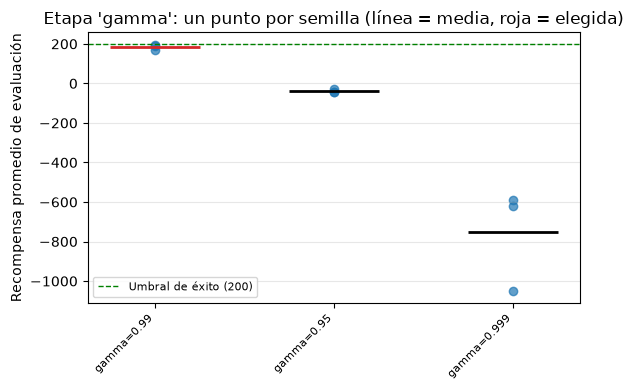

{'gamma=0.95': {'101': {'recompensa_promedio': -29.609867708702424,
   'tasa_exito': 0.02,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size': 100000,
     'tau': 0.01,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [256, 256, 256],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '102': {'recompensa_promedio': -45.659581303902144,
   'tasa_exito': 0.0,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.95,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer

In [12]:
# Etapa 3: factor de descuento
calibrar_etapa('gamma', {'gamma': [0.95, 0.99, 0.999]})

resultados_calibracion_tau.json: 12 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/12] tau=0.01 | semilla 102: recompensa 189.9, éxito 61%
[2/12] tau=0.005 | semilla 100: recompensa 154.9, éxito 47%
[3/12] tau=0.005 | semilla 101: recompensa 263.5, éxito 90%
[4/12] tau=0.01 | semilla 101: recompensa 196.2, éxito 73%
[5/12] tau=0.005 | semilla 102: recompensa 268.7, éxito 92%
[6/12] tau=0.01 | semilla 100: recompensa 169.6, éxito 14%
[7/12] tau=0.001 | semilla 102: recompensa 195.5, éxito 58%
[8/12] tau=0.001 | semilla 101: recompensa 219.5, éxito 80%
[9/12] tau=0.001 | semilla 100: recompensa 170.7, éxito 43%
[10/12] tau=0.0001 | semilla 101: recompensa 119.5, éxito 26%
[11/12] tau=0.0001 | semilla 102: recompensa 87.5, éxito 28%
[12/12] tau=0.0001 | semilla 100: recompensa 48.7, éxito 12%

Etapa 'tau' (3 semillas, 600 episodios)
Configuración    media   desv.    peor   éxito
tau=0.005     229.0    64.3   154.9   76.3%   <- elegida
tau=0.001     195.2    24.4   170.7   60.3%


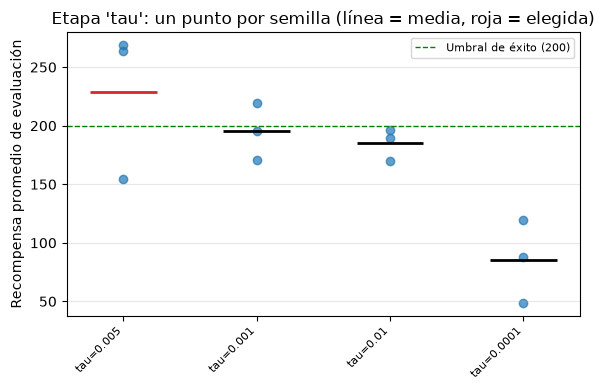

{'tau=0.0001': {'101': {'recompensa_promedio': 119.50671180776841,
   'tasa_exito': 0.26,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size': 100000,
     'tau': 0.0001,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [256, 256, 256],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '102': {'recompensa_promedio': 87.48834028381717,
   'tasa_exito': 0.28,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer

In [13]:
# Etapa 4: tasa del soft update de la red objetivo
calibrar_etapa('tau', {'tau': [1e-4, 1e-3, 5e-3, 1e-2]})

resultados_calibracion_exploracion.json: 18 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/18] epsilon_decay=0.998, epsilon_min=0.01 | semilla 101: recompensa 107.9, éxito 10%
[2/18] epsilon_decay=0.998, epsilon_min=0.01 | semilla 100: recompensa 152.2, éxito 34%
[3/18] epsilon_decay=0.998, epsilon_min=0.01 | semilla 102: recompensa 151.9, éxito 58%
[4/18] epsilon_decay=0.995, epsilon_min=0.05 | semilla 102: recompensa 169.8, éxito 62%
[5/18] epsilon_decay=0.995, epsilon_min=0.01 | semilla 102: recompensa 169.8, éxito 62%
[6/18] epsilon_decay=0.99, epsilon_min=0.01 | semilla 100: recompensa 154.9, éxito 47%
[7/18] epsilon_decay=0.99, epsilon_min=0.05 | semilla 100: recompensa 260.6, éxito 91%
[8/18] epsilon_decay=0.995, epsilon_min=0.05 | semilla 100: recompensa 67.2, éxito 35%
[9/18] epsilon_decay=0.995, epsilon_min=0.01 | semilla 100: recompensa 67.2, éxito 35%
[10/18] epsilon_decay=0.99, epsilon_min=0.01 | semilla 101: recompensa 263.5, éxito 90%
[11/18] epsilon_decay=0.99

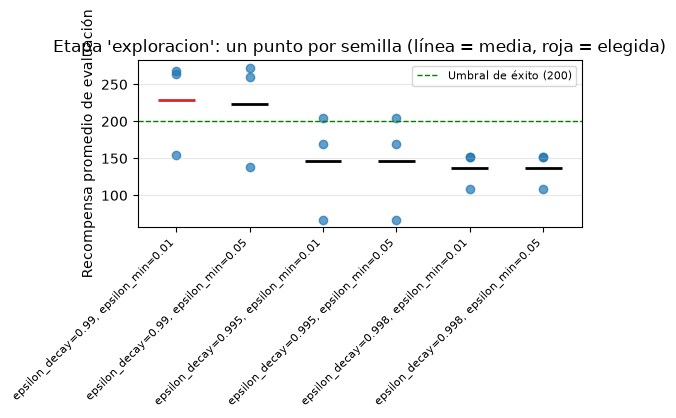

{'epsilon_decay=0.99, epsilon_min=0.01': {'100': {'recompensa_promedio': 154.89693965233778,
   'tasa_exito': 0.47,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size': 100000,
     'tau': 0.005,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [256, 256, 256],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '101': {'recompensa_promedio': 263.5149478020801,
   'tasa_exito': 0.9,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch

In [14]:
# Etapa 5: exploración (decaimiento por episodio y piso de epsilon)
calibrar_etapa('exploracion', {'epsilon_decay': [0.99, 0.995, 0.998], 'epsilon_min': [0.01, 0.05]})

resultados_calibracion_lote_buffer.json: 18 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/18] batch_size=32, buffer_size=20000 | semilla 100: recompensa 269.5, éxito 93%
[2/18] batch_size=32, buffer_size=20000 | semilla 101: recompensa 173.7, éxito 15%
[3/18] batch_size=64, buffer_size=20000 | semilla 102: recompensa 220.2, éxito 79%
[4/18] batch_size=32, buffer_size=100000 | semilla 100: recompensa 154.9, éxito 47%
[5/18] batch_size=32, buffer_size=20000 | semilla 102: recompensa 247.2, éxito 84%
[6/18] batch_size=32, buffer_size=100000 | semilla 101: recompensa 263.5, éxito 90%
[7/18] batch_size=64, buffer_size=20000 | semilla 101: recompensa 284.9, éxito 100%
[8/18] batch_size=64, buffer_size=20000 | semilla 100: recompensa 111.1, éxito 29%
[9/18] batch_size=32, buffer_size=100000 | semilla 102: recompensa 268.7, éxito 92%
[10/18] batch_size=64, buffer_size=100000 | semilla 102: recompensa 192.4, éxito 62%
[11/18] batch_size=128, buffer_size=20000 | semilla 101: recompens

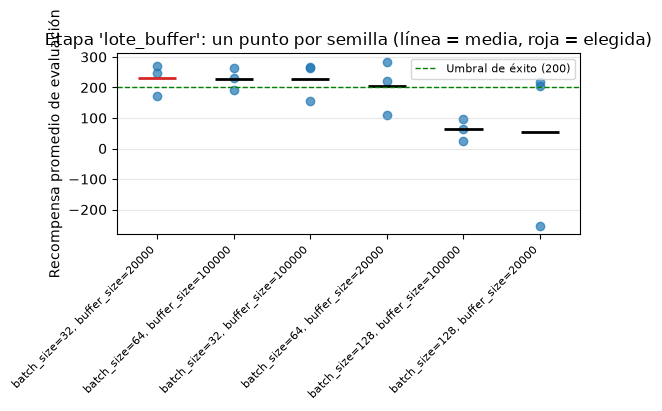

{'batch_size=32, buffer_size=20000': {'100': {'recompensa_promedio': 269.53246836109844,
   'tasa_exito': 0.93,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch_size': 32,
     'buffer_size': 20000,
     'tau': 0.005,
     'epsilon_start': 1.0,
     'epsilon_min': 0.01,
     'epsilon_decay': 0.99,
     'capas_ocultas': [256, 256, 256],
     'usar_target_net': True,
     'usar_replay_buffer': True,
     'usar_huber': True}}},
  '101': {'recompensa_promedio': 173.7332961933524,
   'tasa_exito': 0.15,
   'configuracion': {'episodios_entrenamiento': 600,
    'episodios_evaluacion': 100,
    'semilla_evaluacion': 20000,
    'entrenamiento': {'max_pasos': 1000, 'umbral_resolucion': None},
    'agente': {'semilla': None,
     'gamma': 0.99,
     'lr': 0.0005,
     'batch_siz

In [15]:
# Etapa 6: tamaño del lote y del replay buffer
calibrar_etapa('lote_buffer', {'batch_size': [32, 64, 128], 'buffer_size': [20_000, 100_000]})

In [16]:
# Confirmación: la candidata de la calibración contra la configuración inicial, al presupuesto de la ablación
from scipy import stats

candidata = dict(HIPERPARAMETROS)
cambios = {clave: (HIPERPARAMETROS_INICIALES[clave], valor) for clave, valor in candidata.items()
           if valor != HIPERPARAMETROS_INICIALES[clave]}

if not cambios:
    print("La calibración conservó todos los hiperparámetros iniciales: no hay nada que confirmar.")
else:
    print("La calibración propone cambiar respecto de la configuración inicial:")
    for clave, (antes, despues) in cambios.items():
        print(f"  {clave}: {antes} -> {despues}")

    confirmacion = {"Inicial": dict(HIPERPARAMETROS_INICIALES), "Candidata": candidata}
    resultados_confirmacion = correr_estudio(confirmacion, Path('resultados_calibracion_confirmacion.json'),
                                             SEMILLAS_CONFIRMACION, EPISODIOS_CONFIRMACION,
                                             SEMILLA_EVALUACION_CALIBRACION)

    recompensas = {nombre: np.array([resultados_confirmacion[nombre][str(s)]['recompensa_promedio']
                                     for s in SEMILLAS_CONFIRMACION]) for nombre in confirmacion}
    exitos = {nombre: np.mean([resultados_confirmacion[nombre][str(s)]['tasa_exito']
                               for s in SEMILLAS_CONFIRMACION]) for nombre in confirmacion}

    print(f"\nConfirmación ({len(SEMILLAS_CONFIRMACION)} semillas nuevas, {EPISODIOS_CONFIRMACION} episodios)")
    print(f"{'':<10}" + "".join(f"{'s' + str(s):>7}" for s in SEMILLAS_CONFIRMACION) + f"{'media':>9}{'desv.':>8}{'éxito':>8}")
    for nombre, r in recompensas.items():
        print(f"{nombre:<10}" + "".join(f"{x:7.0f}" for x in r) + f"{r.mean():9.1f}{r.std(ddof=1):8.1f}{exitos[nombre]:8.1%}")

    prueba = stats.mannwhitneyu(recompensas["Candidata"], recompensas["Inicial"], alternative='two-sided', method='exact')
    print(f"Mann-Whitney exacto, candidata contra inicial: U = {prueba.statistic:.1f}, p = {prueba.pvalue:.4f}")

    if recompensas["Candidata"].mean() >= recompensas["Inicial"].mean():
        print("La candidata tiene mayor recompensa media: se adoptan los cambios." + (
            "" if prueba.pvalue < 0.05 else " La diferencia no es significativa con 5 semillas."))
    else:
        HIPERPARAMETROS.clear()
        HIPERPARAMETROS.update(HIPERPARAMETROS_INICIALES)
        print("La candidata no supera a la inicial en media: se descartan los cambios propuestos y se mantienen "
              "los hiperparámetros iniciales.")

La calibración propone cambiar respecto de la configuración inicial:
  gamma: 0.95 -> 0.99
  lr: 0.0001 -> 0.0005
  buffer_size: 100000 -> 20000
  tau: 0.01 -> 0.005
  capas_ocultas: (128, 128) -> (256, 256, 256)
resultados_calibracion_confirmacion.json: 10 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/10] Candidata | semilla 104: recompensa 23.7, éxito 8%
[2/10] Candidata | semilla 107: recompensa 212.8, éxito 61%
[3/10] Candidata | semilla 105: recompensa 219.8, éxito 74%
[4/10] Candidata | semilla 103: recompensa 284.5, éxito 98%
[5/10] Candidata | semilla 106: recompensa 247.6, éxito 88%
[6/10] Inicial | semilla 103: recompensa -77.4, éxito 0%
[7/10] Inicial | semilla 105: recompensa -77.9, éxito 0%
[8/10] Inicial | semilla 106: recompensa -67.6, éxito 0%
[9/10] Inicial | semilla 104: recompensa -39.2, éxito 0%
[10/10] Inicial | semilla 107: recompensa -52.9, éxito 0%

Confirmación (5 semillas nuevas, 900 episodios)
             s103   s104   s105   s106   s107    media 

In [17]:
# Hiperparámetros elegidos: son los que usan las secciones 7 a 11
print("Hiperparámetros elegidos tras la calibración:")
for clave, valor in HIPERPARAMETROS.items():
    inicial = HIPERPARAMETROS_INICIALES[clave]
    print(f"  {clave:<15} = {valor}" + ("" if valor == inicial else f"   (cambió; inicial: {inicial})"))
if HIPERPARAMETROS == HIPERPARAMETROS_INICIALES:
    print("Son los hiperparámetros iniciales: la calibración no encontró cambios que los mejoren.")

Hiperparámetros elegidos tras la calibración:
  gamma           = 0.99   (cambió; inicial: 0.95)
  lr              = 0.0005   (cambió; inicial: 0.0001)
  batch_size      = 32
  buffer_size     = 20000   (cambió; inicial: 100000)
  tau             = 0.005   (cambió; inicial: 0.01)
  epsilon_min     = 0.01
  epsilon_decay   = 0.99
  capas_ocultas   = (256, 256, 256)   (cambió; inicial: (128, 128))


## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


In [18]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA, **HIPERPARAMETROS)

print("\nEntrenando el agente DQN en LunarLander-v3...")
recompensas_episodios, longitudes_episodios = entrenar_agente(
    agente_dqn, env,
    num_episodios=1200,
    max_pasos=1000,
    umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
    semilla=SEMILLA,
    verbose=True,
)

env.close()


Entrenando el agente DQN en LunarLander-v3...
Episodio    60 | Recompensa media (100 ep):  -103.46 | Longitud media:  107.1 | epsilon: 0.547 |    22s
Episodio   120 | Recompensa media (100 ep):   -44.24 | Longitud media:  259.3 | epsilon: 0.299 |    94s
Episodio   180 | Recompensa media (100 ep):     8.36 | Longitud media:  427.5 | epsilon: 0.164 |   187s
Episodio   240 | Recompensa media (100 ep):    25.90 | Longitud media:  251.6 | epsilon: 0.090 |   231s
Episodio   300 | Recompensa media (100 ep):   169.18 | Longitud media:  313.4 | epsilon: 0.049 |   320s
Episodio   360 | Recompensa media (100 ep):   236.55 | Longitud media:  288.8 | epsilon: 0.027 |   383s
Episodio   420 | Recompensa media (100 ep):   227.21 | Longitud media:  262.4 | epsilon: 0.015 |   448s
Episodio   480 | Recompensa media (100 ep):   224.22 | Longitud media:  228.9 | epsilon: 0.010 |   499s
Episodio   540 | Recompensa media (100 ep):   197.28 | Longitud media:  220.3 | epsilon: 0.010 |   558s
Episodio   600 | 

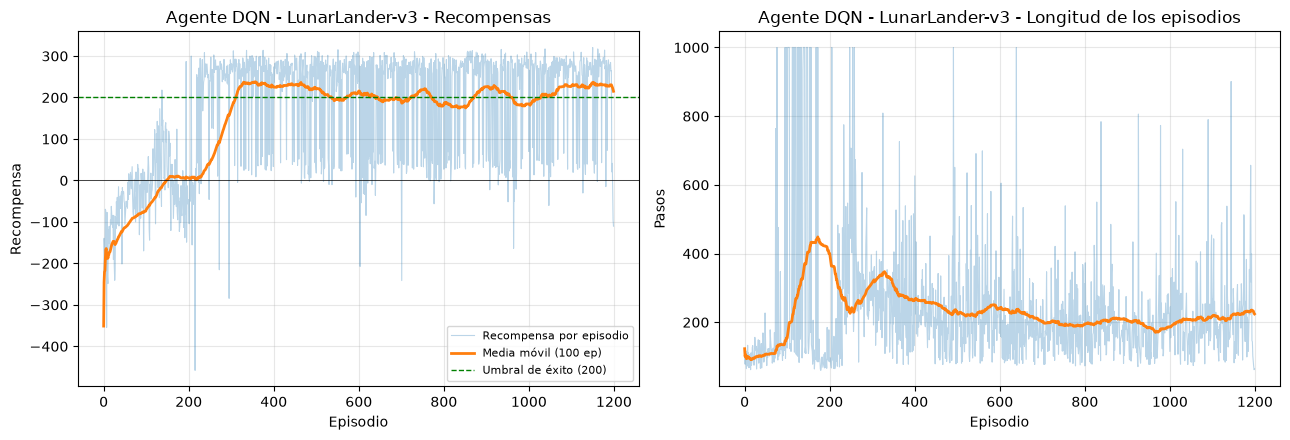

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 215.00
Tasa de éxito (R ≥ 200): 76.0%
Epsilon final: 0.010


In [19]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [20]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [21]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...

Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 50.0%
Recompensa promedio: 156.78
Recompensa mediana:  209.58
Desviación estándar: 140.46
Total de éxitos: 100 / 200

Implementación de referencia para comparar:

Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


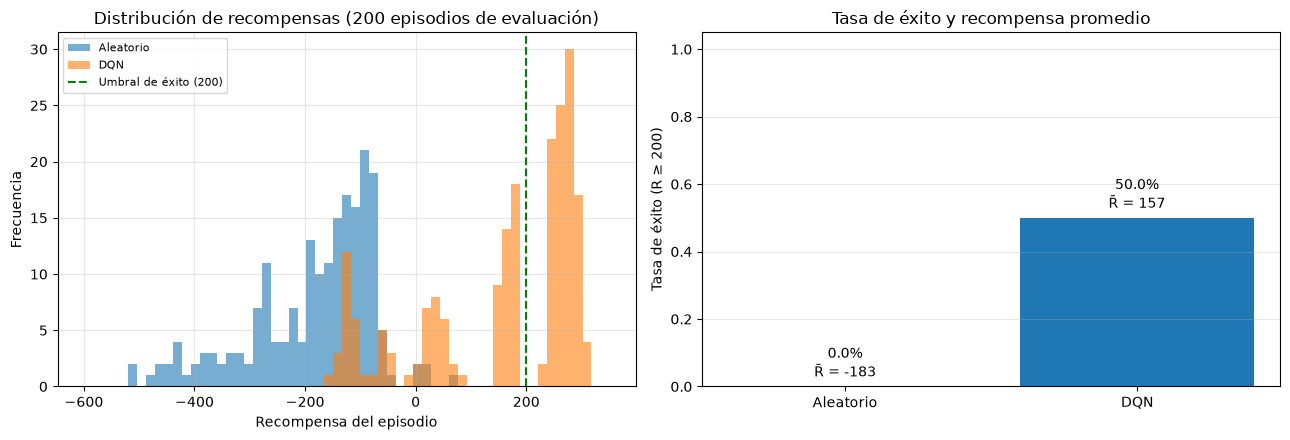

Tasa de éxito DQN:       50.0%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 340.0 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  50.0%
  R ≥  150:  69.0%
  R ≥  100:  70.5%
  R ≥    0:  83.0%
  Episodios que se estrellan (R < -50): 15.0%


In [22]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892: 1000 pasos, recompensa   183.5
  semilla 27739: 1000 pasos, recompensa   168.9
  semilla 26545:  277 pasos, recompensa   243.6
  semilla 24388:  188 pasos, recompensa   275.3
  semilla 24330:   58 pasos, recompensa   -43.2
  semilla 28585:  134 pasos, recompensa    -9.3
  semilla 20859:  175 pasos, recompensa   252.3
  semilla 26973: 1000 pasos, recompensa   201.1
  semilla 22014:  375 pasos, recompensa   257.8
  semilla 20941: 1000 pasos, recompensa   147.3

5/10 episodios exitosos, recompensa media 167.7 → aterrizaje_dqn.gif


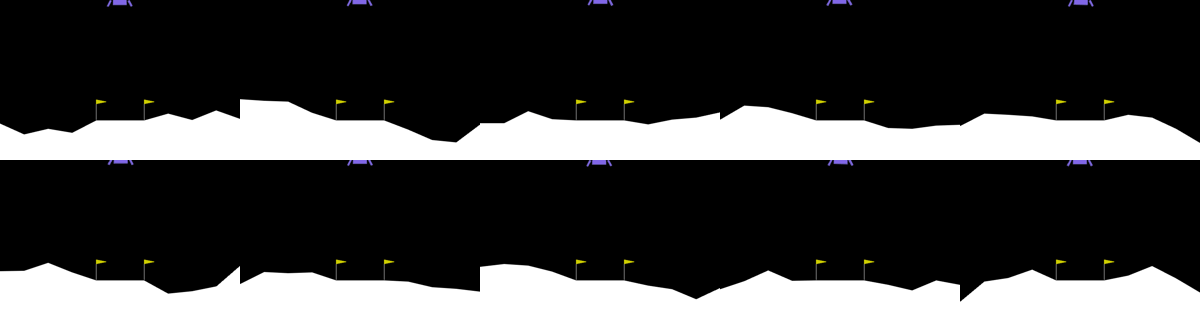

In [23]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


Control del descenso — variables fijas: x=0, vx=0, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — variables fijas: y=0.7, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control de la orientación — variables fijas: x=0, y=0.7, vx=0, vy=-0.3, c_izq=0, c_der=0


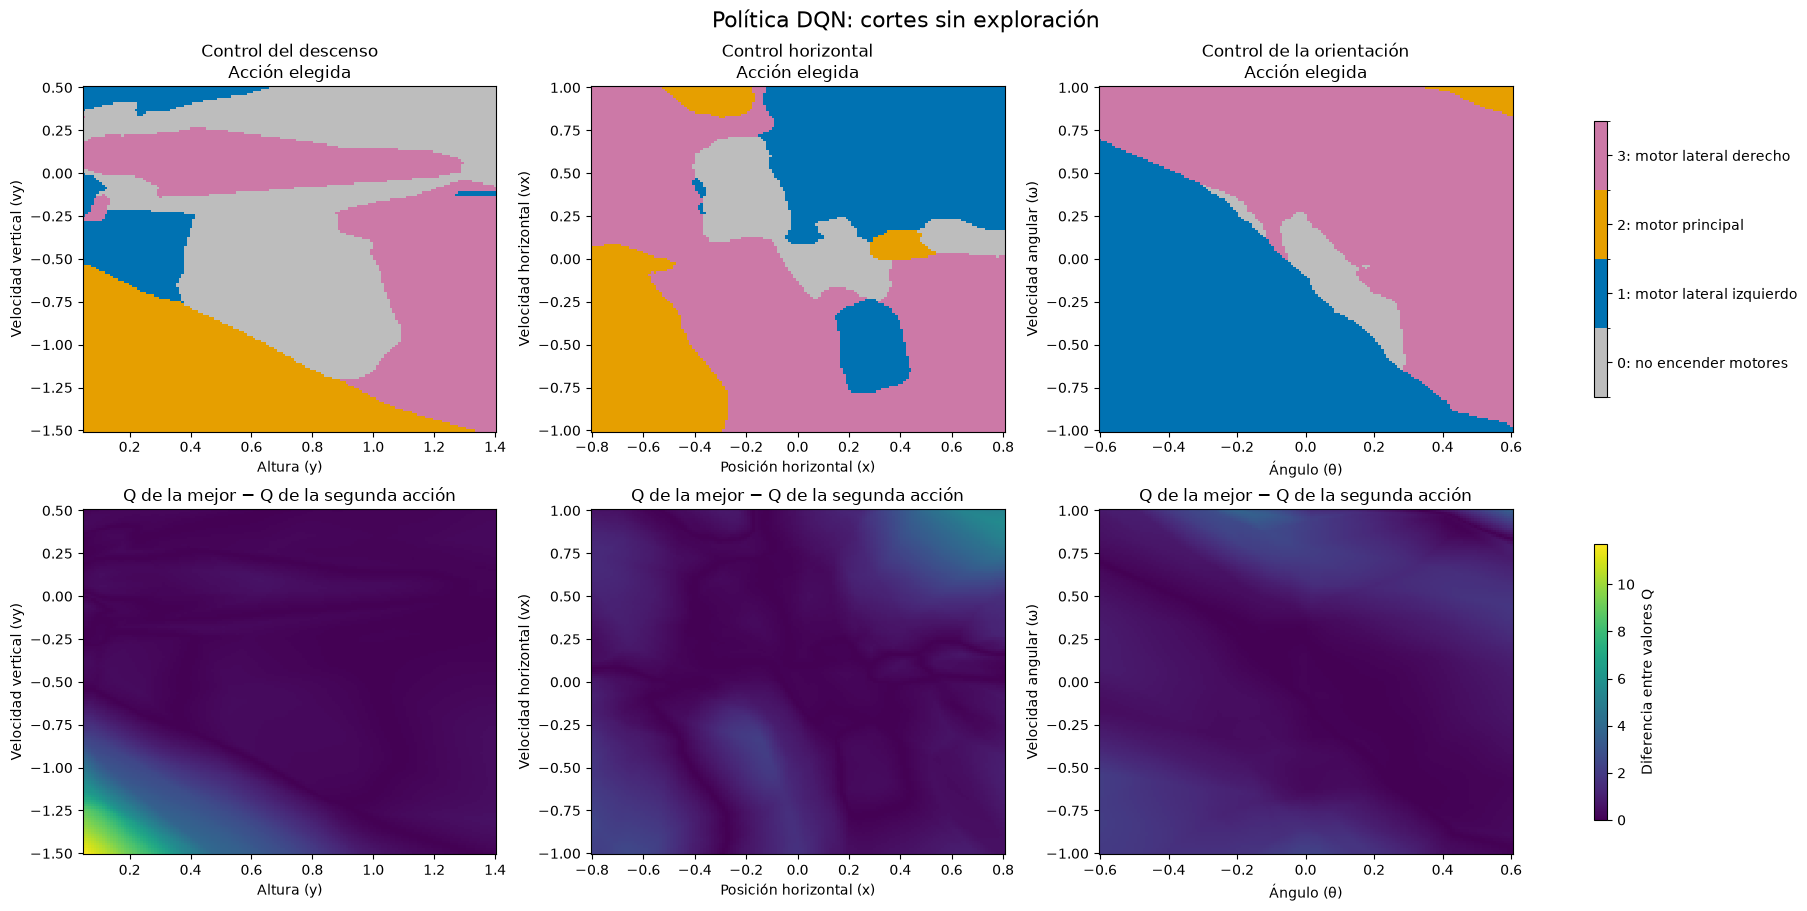

In [24]:
# Análisis de la política aprendida mediante cortes del estado.
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.colors import ListedColormap, BoundaryNorm

# Orden de las variables:
# [x, y, vx, vy, angulo, velocidad_angular, contacto_izq, contacto_der]
nombres_estado = ["x", "y", "vx", "vy", "θ", "ω", "c_izq", "c_der"]

nombres_acciones = [
    "0: no encender motores",
    "1: motor lateral izquierdo",
    "2: motor principal",
    "3: motor lateral derecho",
]

# Cada corte modifica dos variables y mantiene las otras seis fijas.
# Los valores son coordenadas del espacio de observación de LunarLander.
cortes = [
    {
        "titulo": "Control del descenso",
        "indices": (1, 3),
        "rangos": ((0.05, 1.4), (-1.5, 0.5)),
        "etiquetas": ("Altura (y)", "Velocidad vertical (vy)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
    {
        "titulo": "Control horizontal",
        "indices": (0, 2),
        "rangos": ((-0.8, 0.8), (-1.0, 1.0)),
        "etiquetas": ("Posición horizontal (x)", "Velocidad horizontal (vx)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
    {
        "titulo": "Control de la orientación",
        "indices": (4, 5),
        "rangos": ((-0.6, 0.6), (-1.0, 1.0)),
        "etiquetas": ("Ángulo (θ)", "Velocidad angular (ω)"),
        "base": [0, 0.7, 0, -0.3, 0, 0, 0, 0],
    },
]

def analizar_cortes_politica(agente, cortes, resolucion=151):
    red = agente.red_q
    parametro = next(red.parameters())
    modo_previo = red.training
    resultados = []

    red.eval()
    try:
        with torch.no_grad():
            for corte in cortes:
                i, j = corte["indices"]

                eje_x = np.linspace(*corte["rangos"][0], resolucion)
                eje_y = np.linspace(*corte["rangos"][1], resolucion)
                X, Y = np.meshgrid(eje_x, eje_y)

                # Construir un estado de ocho variables por punto de la grilla.
                estados = np.tile(
                    np.asarray(corte["base"], dtype=np.float32),
                    (X.size, 1),
                )
                estados[:, i] = X.ravel()
                estados[:, j] = Y.ravel()

                estados_t = torch.as_tensor(
                    estados,
                    dtype=parametro.dtype,
                    device=parametro.device,
                )

                # Consulta directa de la red: sin exploración ni aprendizaje.
                q = red(estados_t).cpu().numpy()
                acciones = q.argmax(axis=1).reshape(X.shape)

                # Margen entre la mejor acción y la segunda mejor.
                q_ordenados = np.sort(q, axis=1)
                margen = (
                    q_ordenados[:, -1] - q_ordenados[:, -2]
                ).reshape(X.shape)

                resultados.append({
                    "corte": corte,
                    "X": X,
                    "Y": Y,
                    "acciones": acciones,
                    "margen": margen,
                    "q": q.reshape(*X.shape, q.shape[1]),
                })
    finally:
        red.train(modo_previo)

    colores = ListedColormap(["#bdbdbd", "#0072b2", "#e69f00", "#cc79a7"])
    norma_acciones = BoundaryNorm(np.arange(-0.5, 4.5, 1), colores.N)

    # Misma escala de margen para poder comparar los tres cortes.
    margen_maximo = max(float(r["margen"].max()) for r in resultados)
    margen_maximo = max(margen_maximo, 1e-8)

    fig, ejes = plt.subplots(
        2, len(resultados),
        figsize=(18, 9),
        squeeze=False,
        constrained_layout=True,
    )

    for columna, resultado in enumerate(resultados):
        corte = resultado["corte"]
        i, j = corte["indices"]

        fijos = ", ".join(
            f"{nombre}={corte['base'][k]:g}"
            for k, nombre in enumerate(nombres_estado)
            if k not in (i, j)
        )
        print(f"{corte['titulo']} — variables fijas: {fijos}")

        mapa_acciones = ejes[0, columna].pcolormesh(
            resultado["X"], resultado["Y"], resultado["acciones"],
            cmap=colores, norm=norma_acciones, shading="auto",
        )
        ejes[0, columna].set_title(
            f"{corte['titulo']}\nAcción elegida", fontsize=12
        )

        mapa_margen = ejes[1, columna].pcolormesh(
            resultado["X"], resultado["Y"], resultado["margen"],
            cmap="viridis", vmin=0, vmax=margen_maximo, shading="auto",
        )
        ejes[1, columna].set_title("Q de la mejor − Q de la segunda acción")

        for fila in range(2):
            ejes[fila, columna].set_xlabel(corte["etiquetas"][0])
            ejes[fila, columna].set_ylabel(corte["etiquetas"][1])

    barra_acciones = fig.colorbar(
        mapa_acciones, ax=ejes[0, :].tolist(),
        ticks=range(4), shrink=0.8,
    )
    barra_acciones.ax.set_yticklabels(nombres_acciones)

    barra_margen = fig.colorbar(
        mapa_margen, ax=ejes[1, :].tolist(), shrink=0.8,
    )
    barra_margen.set_label("Diferencia entre valores Q")

    fig.suptitle("Política DQN: cortes sin exploración", fontsize=16)
    plt.show()

    return resultados


resultados_cortes = analizar_cortes_politica(agente_dqn, cortes)

Control horizontal — altura 0.2 — variables fijas: y=0.2, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — altura 0.7 — variables fijas: y=0.7, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0
Control horizontal — altura 1.2 — variables fijas: y=1.2, vy=-0.3, θ=0, ω=0, c_izq=0, c_der=0


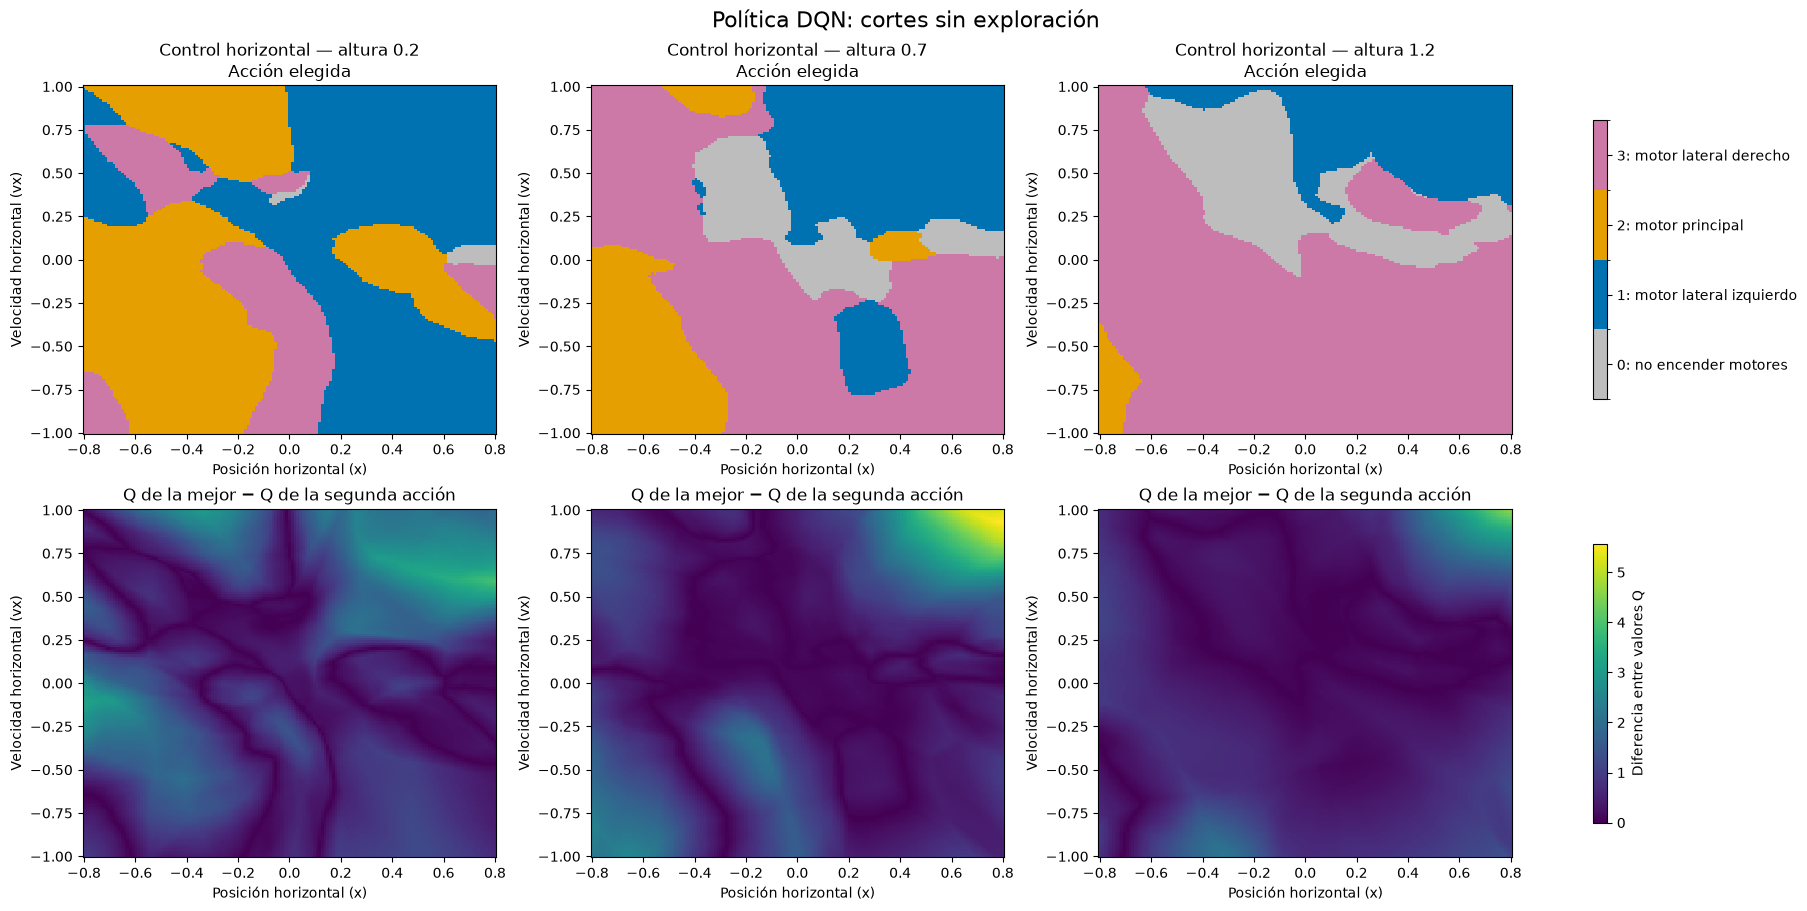

Orientación — altura 0.2 — variables fijas: x=0, y=0.2, vx=0, vy=-0.3, c_izq=0, c_der=0
Orientación — altura 0.7 — variables fijas: x=0, y=0.7, vx=0, vy=-0.3, c_izq=0, c_der=0
Orientación — altura 1.2 — variables fijas: x=0, y=1.2, vx=0, vy=-0.3, c_izq=0, c_der=0


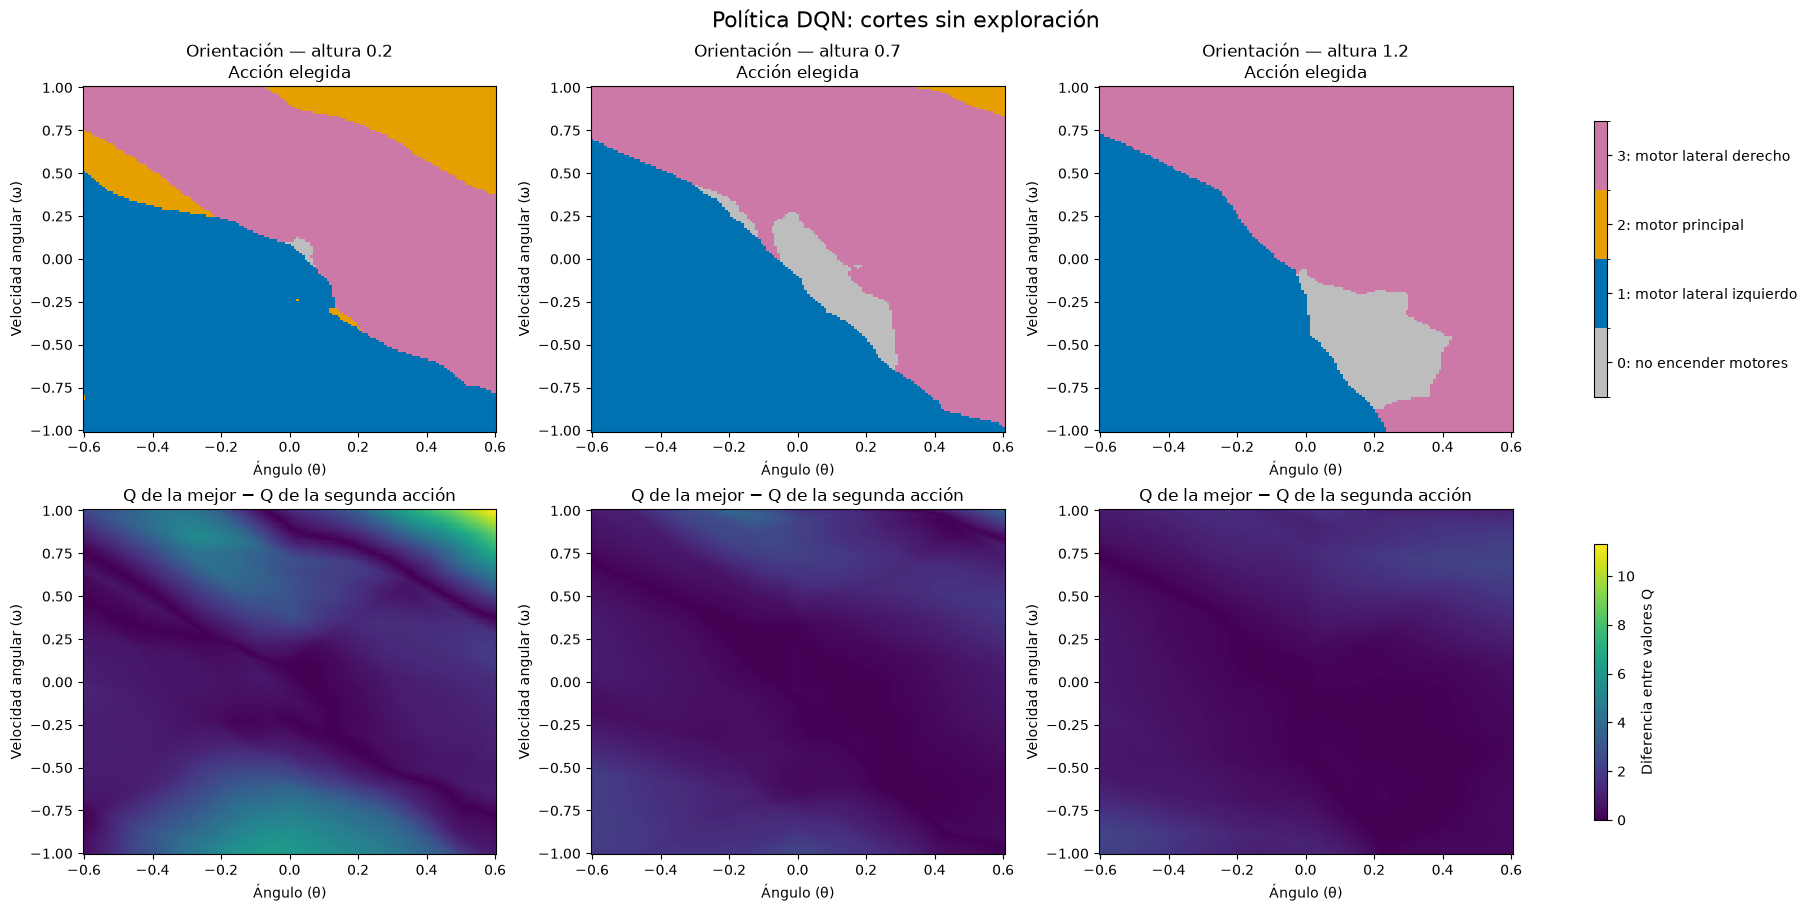

In [25]:
# Comparar la política a distintas alturas.
# Requiere ejecutar antes la celda que define analizar_cortes_politica.

alturas = [0.2, 0.7, 1.2]

# 1. CONTROL HORIZONTAL
# Variamos x y vx.
# Fijamos vy=-0.3, ángulo=0, velocidad angular=0 y contactos=0.
cortes_horizontal = [
    {
        "titulo": f"Control horizontal — altura {altura:g}",
        "indices": (0, 2),
        "rangos": ((-0.8, 0.8), (-1.0, 1.0)),
        "etiquetas": (
            "Posición horizontal (x)",
            "Velocidad horizontal (vx)",
        ),
        "base": [0, altura, 0, -0.3, 0, 0, 0, 0],
    }
    for altura in alturas
]

resultados_horizontal = analizar_cortes_politica(
    agente_dqn, cortes_horizontal
)

# 2. CONTROL DE LA ORIENTACIÓN
# Variamos ángulo y velocidad angular.
# Fijamos x=0, vx=0, vy=-0.3 y contactos=0.
cortes_orientacion = [
    {
        "titulo": f"Orientación — altura {altura:g}",
        "indices": (4, 5),
        "rangos": ((-0.6, 0.6), (-1.0, 1.0)),
        "etiquetas": (
            "Ángulo (θ)",
            "Velocidad angular (ω)",
        ),
        "base": [0, altura, 0, -0.3, 0, 0, 0, 0],
    }
    for altura in alturas
]

resultados_orientacion = analizar_cortes_politica(
    agente_dqn, cortes_orientacion
)

## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


In [26]:
# TODO 3: estudio de ablación
from scipy import stats

EPISODIOS_ABLACION = 900                  # menos que los 1200 del entrenamiento principal, para acotar el cómputo
SEMILLAS_ENTRENAMIENTO = list(range(10))
ARCHIVO_ABLACION = Path('resultados_ablacion.json')

# Cada variante desactiva un único componente; el resto queda igual al DQN completo, con los
# hiperparámetros elegidos en la calibración. La infraestructura (en paralelo, con la configuración
# guardada junto a cada resultado) es la de la sección 6.1.
cambios_por_variante = {
    "DQN completo": {},
    "Sin target network": {"usar_target_net": False},
    "Sin replay buffer": {"usar_replay_buffer": False},
    "Pérdida MSE (sin Huber)": {"usar_huber": False},
}
variantes = {nombre: {**HIPERPARAMETROS, **cambios} for nombre, cambios in cambios_por_variante.items()}

resultados_ablacion = correr_estudio(variantes, ARCHIVO_ABLACION, SEMILLAS_ENTRENAMIENTO, EPISODIOS_ABLACION)

DQN completo | semilla 0: la corrida guardada usó otra configuración, se reentrena
DQN completo | semilla 1: la corrida guardada usó otra configuración, se reentrena
DQN completo | semilla 2: la corrida guardada usó otra configuración, se reentrena
resultados_ablacion.json: 40 corridas por entrenar en 15 procesos (0 ya guardadas)
[1/40] Sin target network | semilla 1: recompensa -553.6, éxito 0%
[2/40] Sin target network | semilla 3: recompensa -553.6, éxito 0%
[3/40] Sin target network | semilla 4: recompensa -553.6, éxito 0%
[4/40] Sin target network | semilla 5: recompensa -553.6, éxito 0%
[5/40] Sin target network | semilla 6: recompensa -563.0, éxito 0%
[6/40] Sin target network | semilla 7: recompensa -553.6, éxito 0%
[7/40] Sin target network | semilla 8: recompensa -563.0, éxito 0%
[8/40] Sin target network | semilla 0: recompensa -553.6, éxito 0%
[9/40] Sin target network | semilla 2: recompensa -553.6, éxito 0%
[10/40] DQN completo | semilla 5: recompensa 228.8, éxito 78%
[11

In [27]:
# Recompensa de evaluación por semilla y test estadístico contra el DQN completo
def por_semilla(nombre, campo='recompensa_promedio'):
    return np.array([resultados_ablacion[nombre][str(s)][campo] for s in SEMILLAS_ENTRENAMIENTO])


def holm(p_valores):
    """Corrección de Holm: devuelve los p ajustados en el mismo orden que los recibidos.
    Controla la probabilidad de algún falso positivo igual que Bonferroni, con más potencia."""
    p = np.asarray(p_valores, dtype=float)
    ajustados = np.empty(len(p))
    maximo = 0.0
    for rango, i in enumerate(np.argsort(p)):
        maximo = max(maximo, (len(p) - rango) * p[i])   # el p ajustado nunca baja al avanzar en el orden
        ajustados[i] = min(1.0, maximo)
    return ajustados


completo = por_semilla("DQN completo")
comparadas = [nombre for nombre in variantes if nombre != "DQN completo"]
num_comparaciones = len(comparadas)

# Mann-Whitney U exacto: con 10 semillas por grupo no se puede asumir normalidad (y no hay empates,
# que es lo que pide el cálculo exacto). Bilateral: la variante podría ser mejor o peor.
pruebas = {nombre: stats.mannwhitneyu(por_semilla(nombre), completo, alternative='two-sided', method='exact')
           for nombre in comparadas}
# Holm corrige por comparar cada variante contra el mismo DQN completo
p_holm = dict(zip(comparadas, holm([pruebas[nombre].pvalue for nombre in comparadas])))

print(f"{'Variante':<25}" + "".join(f"{'s' + str(s):>7}" for s in SEMILLAS_ENTRENAMIENTO)
      + f"{'media':>8}{'éxito':>8}{'U':>7}{'p':>8}{'p Holm':>8}")

for nombre in variantes:
    recompensas = por_semilla(nombre)
    fila = (f"{nombre:<25}" + "".join(f"{r:7.0f}" for r in recompensas)
            + f"{recompensas.mean():8.1f}{por_semilla(nombre, 'tasa_exito').mean():8.1%}")

    if nombre != "DQN completo":
        fila += f"{pruebas[nombre].statistic:7.1f}{pruebas[nombre].pvalue:8.4f}{p_holm[nombre]:8.4f}"
    print(fila)

print(f"\n{len(SEMILLAS_ENTRENAMIENTO)} semillas de entrenamiento, {EPISODIOS_ABLACION} episodios, "
      f"evaluación sobre {EPISODIOS_EVALUACION} episodios sin exploración (recompensa promedio por semilla).")

Variante                      s0     s1     s2     s3     s4     s5     s6     s7     s8     s9   media   éxito      U       p  p Holm
DQN completo                 196    245    245    158    277    229     82    277    239    176   212.4   68.9%
Sin target network          -554   -554   -554   -554   -554   -554   -563   -554   -563   -563  -556.4    0.0%    0.0  0.0000  0.0000
Sin replay buffer           -556    -55   -178   -168   -147    115   -177   -234   -106   -141  -164.5    3.9%    1.0  0.0000  0.0000
Pérdida MSE (sin Huber)      180    281    232    171    146    259    220    251    182    279   220.0   72.7%   54.0  0.7959  0.7959

10 semillas de entrenamiento, 900 episodios, evaluación sobre 100 episodios sin exploración (recompensa promedio por semilla).


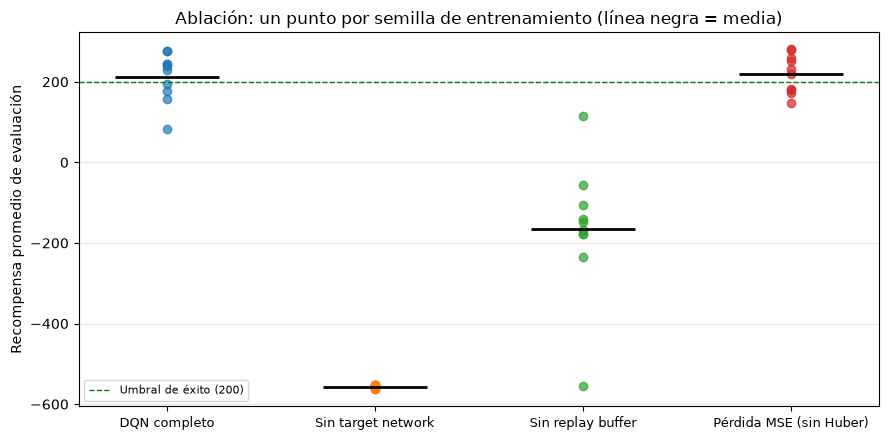

In [28]:
# Recompensa de evaluación por semilla de cada variante
fig, ax = plt.subplots(figsize=(9, 4.5))

for posicion, nombre in enumerate(variantes):
    recompensas = por_semilla(nombre)
    ax.scatter([posicion] * len(recompensas), recompensas, alpha=0.7, label=None)
    ax.hlines(recompensas.mean(), posicion - 0.25, posicion + 0.25, color='black', linewidth=2)

ax.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
ax.set_xticks(range(len(variantes)))
ax.set_xticklabels(variantes, fontsize=9)
ax.set_ylabel("Recompensa promedio de evaluación")
ax.set_title("Ablación: un punto por semilla de entrenamiento (línea negra = media)")
ax.legend(fontsize=8)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


### Cómo leer los resultados de la ablación

* **Tabla.** Cada fila es una variante y cada columna una semilla de entrenamiento: el valor es la
  recompensa promedio de evaluación de esa corrida. `éxito` es la tasa de éxito promedio entre semillas.
* **U y p.** El test compara las 10 recompensas de la variante contra las 10 del DQN completo. `p` chico
  indica que es poco probable que ambos grupos vengan de la misma distribución. `p Holm` es el `p` ajustado
  por hacer tres comparaciones contra el mismo DQN completo (corrección de Holm) y es el que se compara con 0.05.
* **Sin significancia no es "sin efecto".** Si una variante es muy variable entre semillas, puede ser peor en
  promedio y aun así no dar significativo.
* **Dirección.** El test es bilateral, así que `p` chico también puede significar que la variante es
  *mejor* que el completo. Hay que mirar el signo de la diferencia de medias.

La celda siguiente resume cada variante con la diferencia de medias, la dispersión entre semillas y la
probabilidad de superioridad.

In [29]:
# Resumen por variante: tamaño y dirección del efecto, no solo el p-valor
ALFA = 0.05

print(f"{'Variante':<25}{'media':>8}{'desv.':>8}{'mediana':>9}{'peor':>8}{'mejor':>8}"
      f"{'R≥200':>8}{'Δ media':>9}{'P(sup.)':>9}   veredicto")

for nombre in variantes:
    recompensas = por_semilla(nombre)
    fila = (f"{nombre:<25}{recompensas.mean():8.1f}{recompensas.std(ddof=1):8.1f}"
            f"{np.median(recompensas):9.1f}{recompensas.min():8.1f}{recompensas.max():8.1f}"
            f"{(recompensas >= UMBRAL_EXITO).sum():>5}/{len(recompensas)}")

    if nombre == "DQN completo":
        print(fila)
        continue

    diferencia = recompensas.mean() - completo.mean()
    # Probabilidad de superioridad: chance de que una corrida de la variante supere a una del completo
    prob_superioridad = pruebas[nombre].statistic / (len(recompensas) * len(completo))

    if p_holm[nombre] >= ALFA:
        veredicto = "sin diferencia significativa"
    else:
        veredicto = "significativamente peor" if diferencia < 0 else "significativamente mejor"
    print(f"{fila}{diferencia:9.1f}{prob_superioridad:9.2f}   {veredicto}")

print(f"\nΔ media = media de la variante − media del DQN completo. P(sup.) = 0.5 significa solapamiento total; "
      f"0 o 1, grupos sin solapar.\nVeredicto con p corregido (Holm) y α = {ALFA}.")

Variante                    media   desv.  mediana    peor   mejor   R≥200  Δ media  P(sup.)   veredicto
DQN completo                212.4    60.5    234.0    82.4   277.4    6/10
Sin target network         -556.4     4.6   -553.6  -563.0  -553.6    0/10   -768.8     0.00   significativamente peor
Sin replay buffer          -164.5   167.6   -157.2  -555.7   115.3    0/10   -376.9     0.01   significativamente peor
Pérdida MSE (sin Huber)     220.0    47.8    225.6   146.3   280.5    6/10      7.7     0.54   sin diferencia significativa

Δ media = media de la variante − media del DQN completo. P(sup.) = 0.5 significa solapamiento total; 0 o 1, grupos sin solapar.
Veredicto con p corregido (Holm) y α = 0.05.


### Qué mide el test de Mann-Whitney

Se ordenan las 20 recompensas (10 de la variante y 10 del DQN completo) y se mira en qué posiciones
quedaron las de la variante. **U** cuenta, sobre todos los pares (corrida de la variante, corrida del
completo), en cuántos gana la variante: va de 0 (la variante pierde siempre) a 100 (gana siempre) y
**U = 50** es el solapamiento total.

La hipótesis nula dice que las dos configuraciones son iguales, de modo que cualquier reparto de las 20 corridas
en dos grupos de 10 sería igual de probable. Hay 184 756 repartos posibles; el gráfico muestra la distribución de U
sobre todos ellos. El **p-valor** es la probabilidad, bajo esa hipótesis, de obtener un U al menos tan alejado de
50 como el observado: es la fracción de barras rojas.

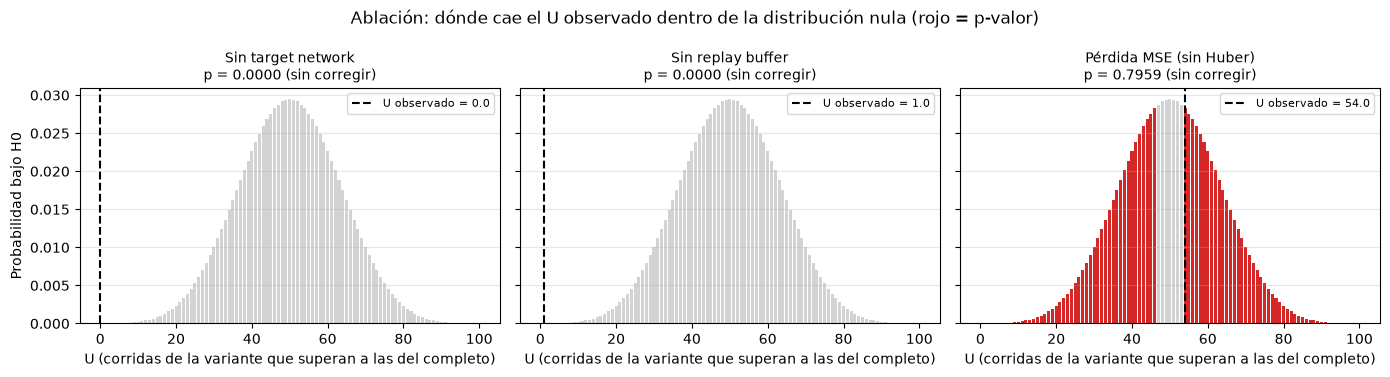

In [30]:
# Distribución exacta de U bajo la hipótesis nula, con el U observado de cada variante
from itertools import combinations

n = len(completo)
# Todas las formas de repartir los rangos 1..2n entre los dos grupos (sin empates)
u_nulo = np.array([sum(rangos) - n * (n + 1) / 2 for rangos in combinations(range(1, 2 * n + 1), n)])
valores, frecuencias = np.unique(u_nulo, return_counts=True)

fig, ejes = plt.subplots(1, num_comparaciones, figsize=(14, 3.8), sharey=True)

for eje, nombre in zip(ejes, comparadas):
    u, p = pruebas[nombre].statistic, pruebas[nombre].pvalue
    # Reparticiones tan o más extremas que la observada (a cualquiera de los dos lados)
    extremos = np.abs(valores - n * n / 2) >= abs(u - n * n / 2)

    eje.bar(valores, frecuencias / len(u_nulo), color=np.where(extremos, 'tab:red', 'lightgray'))
    eje.axvline(u, color='black', linestyle='--', label=f"U observado = {u:.1f}")
    eje.set_title(f"{nombre}\np = {p:.4f} (sin corregir)", fontsize=10)
    eje.set_xlabel("U (corridas de la variante que superan a las del completo)")
    eje.legend(fontsize=8)
    eje.grid(True, axis='y', alpha=0.3)

ejes[0].set_ylabel("Probabilidad bajo H0")
fig.suptitle("Ablación: dónde cae el U observado dentro de la distribución nula (rojo = p-valor)")
plt.tight_layout()
plt.show()

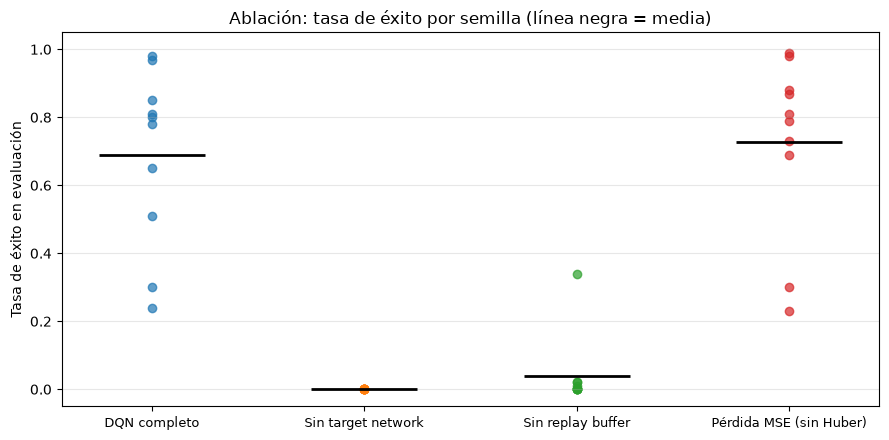

In [31]:
# Tasa de éxito (R ≥ 200) de evaluación por semilla de cada variante
fig, ax = plt.subplots(figsize=(9, 4.5))

for posicion, nombre in enumerate(variantes):
    tasas = por_semilla(nombre, 'tasa_exito')
    ax.scatter([posicion] * len(tasas), tasas, alpha=0.7)
    ax.hlines(tasas.mean(), posicion - 0.25, posicion + 0.25, color='black', linewidth=2)

ax.set_xticks(range(len(variantes)))
ax.set_xticklabels(variantes, fontsize=9)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito en evaluación")
ax.set_title("Ablación: tasa de éxito por semilla (línea negra = media)")
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
